In [4]:
from pathlib import Path
import os
import pandas as pd

import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "globals.json").exists())
os.chdir(REPO)  # all paths are relative to the repo root

TAG, K = "y2022", 15          # K = 15 or 30 (both were fit for y2022)
RES = Path("output/lda_cleaned") / TAG
T = [f"t{i}" for i in range(1, K + 1)]

In [5]:
# one row per meeting: id, leaid, year, split, t1..tK, modeled_tokens
meetings = pd.read_parquet(RES / f"theta_meetings_k{K}.parquet")
meetings["leaid"] = meetings["leaid"].astype(str).str.zfill(7)

# one row per district: equal weight per meeting (long meetings don't dominate)
district = meetings.groupby("leaid")[T].mean()
district["n_meetings"] = meetings.groupby("leaid").size()
district = district.reset_index()

# weight by meeting length
# w = meetings[T].mul(meetings["modeled_tokens"], axis=0)
# district = w.groupby(meetings["leaid"]).sum().div(meetings.groupby("leaid")["modeled_tokens"].sum(), axis=0)

print(f"{len(meetings):,} meetings -> {len(district):,} districts; "
      f"rows sum to 1: {district[T].sum(axis=1).round(6).eq(1).all()}")
district.head()

1,237 meetings -> 714 districts; rows sum to 1: True


,leaid,t1,t2,t3,t4,t5,t6,t7,t8,t9,t10,t11,t12,t13,t14,t15,n_meetings
0,0100007,0.013410,0.125555,0.000313,0.039253,0.004431,0.142246,0.051882,0.046508,0.046677,0.039439,0.059115,0.009655,0.083192,0.272073,0.066253,1
1,0101320,0.006779,0.041889,0.000353,0.059405,0.000353,0.135589,0.000353,0.081192,0.231409,0.124692,0.000353,0.003475,0.000353,0.021791,0.292014,1
2,0102100,0.028763,0.081055,0.000295,0.012315,0.006777,0.157607,0.103664,0.120183,0.128713,0.163238,0.003055,0.083463,0.000432,0.087345,0.023095,1
3,0102520,0.011038,0.090753,0.002111,0.000295,0.013414,0.150936,0.010859,0.006536,0.230370,0.027169,0.026880,0.003109,0.003649,0.229020,0.193861,1
4,0102820,0.014605,0.052181,0.000365,0.155548,0.000365,0.111322,0.085862,0.112277,0.000365,0.403186,0.009213,0.000365,0.053614,0.000365,0.000365,1


In [2]:
# add district covariates
# static = pd.read_parquet("Datastore/District Covariates/processed/district_static.parquet")
# district = district.merge(static[["leaid", "lea_name", "state_location", "locale", "gop_2p_2020"]], on="leaid", how="left")

## SVD

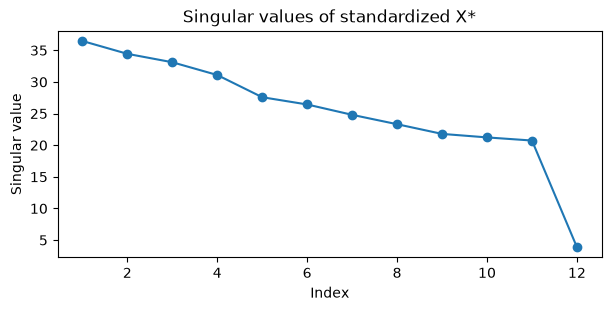

In [38]:
MIN_MEETINGS = 1        # raise (e.g. 3) to drop districts with noisy profiles
STANDARDIZE = True      # True: SVD of standardized X* (lecture); False: raw topic weights + SCORE
MIN_TOPIC_MEAN = 0.02    # e.g. 0.02 drops rare topics (t3, t5, t11) before SVD; standardizing inflates their noise

d = district[district["n_meetings"] >= MIN_MEETINGS].reset_index(drop=True)
TS = [t for t in T if d[t].mean() >= MIN_TOPIC_MEAN]     # topics used in the SVD
X_raw = d[TS].to_numpy()                                 # n_districts x topics, rows sum to 1

if STANDARDIZE:
    X = (X_raw - X_raw.mean(0)) / X_raw.std(0)           # each topic: mean 0, SD 1
else:
    X = X_raw

U, s, Vt = np.linalg.svd(X, full_matrices=False)
if not STANDARDIZE:
    U[:, 0] *= np.sign(U[:, 0].sum())                    # fix sign so the 1st vector is positive (SCORE)

fig, ax = plt.subplots(figsize=(6, 3), layout="constrained")
ax.plot(range(1, len(s) + 1), s, "o-")
ax.set(xlabel="Index", ylabel="Singular value",
       title=f"Singular values of {'standardized X*' if STANDARDIZE else 'raw district × topic matrix'}")
plt.show()


In [39]:
# MIN_MEETINGS = 1     # raise (e.g. 3) to drop districts with noisy profiles
# SCORE = True         # True: divide by the 1st singular vector (Jin's SCORE); False: plain U[:, :r]

# d = district[district["n_meetings"] >= MIN_MEETINGS].reset_index(drop=True)
# X = d[T].to_numpy()                       # n_districts x K, rows sum to 1

# U, s, Vt = np.linalg.svd(X, full_matrices=False)
# U[:, 0] *= np.sign(U[:, 0].sum())         # fix sign so the 1st vector is positive

# # scree plot to choose r (number of singular vectors kept)
# fig, ax = plt.subplots(figsize=(6, 3), layout="constrained")
# ax.plot(range(1, len(s) + 1), s, "o-")
# ax.set(xlabel="Index", ylabel="Singular value", title="Singular values of district × topic matrix")
# plt.show()

### Choose k

In [40]:
def embed(r):
    """r-dimensional spectral embedding"""
    if STANDARDIZE:
        return U[:, :r]                      # lecture: top r left singular vectors of X*
    return U[:, 1:r + 1] / U[:, [0]]         # SCORE: r ratio columns U[:, j] / U[:, 0]

# silhouette for each (r, k); the lecture's rule is r = k - 1 (marked *)
for r in range(1, 6):
    row = []
    for k in range(2, 9):
        Z = embed(r)
        sil = silhouette_score(Z, KMeans(k, n_init=20, random_state=0).fit_predict(Z))
        row.append(f"k={k}:{sil:.2f}{'*' if r == k - 1 else ' '}")
    print(f"r={r}: " + "  ".join(row))


r=1: k=2:0.55*  k=3:0.52   k=4:0.53   k=5:0.53   k=6:0.52   k=7:0.54   k=8:0.53 
r=2: k=2:0.32   k=3:0.36*  k=4:0.34   k=5:0.32   k=6:0.33   k=7:0.32   k=8:0.32 
r=3: k=2:0.22   k=3:0.24   k=4:0.27*  k=5:0.26   k=6:0.25   k=7:0.23   k=8:0.24 
r=4: k=2:0.17   k=3:0.19   k=4:0.21   k=5:0.23*  k=6:0.22   k=7:0.20   k=8:0.19 
r=5: k=2:0.14   k=3:0.15   k=4:0.17   k=5:0.18   k=6:0.19*  k=7:0.19   k=8:0.17 


In [41]:
# def embed(r):
#     if SCORE:  # ratios U[:,j]/U[:,0], j = 2..r: removes district-level scale, keeps direction
#         return U[:, 1:r] / U[:, [0]]
#     return U[:, :r]

# # choose k (and check r) by silhouette
# for r in (2, 3, 4, 5, 6):
#     Z = embed(r)
#     sil = {k: silhouette_score(Z, KMeans(k, n_init=20, random_state=0).fit_predict(Z)) for k in range(2, 9)}
#     print(f"r={r}: " + "  ".join(f"k={k}:{v:.2f}" for k, v in sil.items()))


cluster
0    185
1    152
2    129
3    154
4     94
Name: count, dtype: int64
v1  low: ['t2', 't13', 't7', 't12']   high: ['t8', 't4', 't15', 't9']
v2  low: ['t12', 't8', 't1', 't7']   high: ['t2', 't9', 't10', 't6']
v3  low: ['t14', 't7', 't6', 't15']   high: ['t12', 't4', 't10', 't13']
v4  low: ['t1', 't15', 't12', 't9']   high: ['t7', 't10', 't4', 't8']


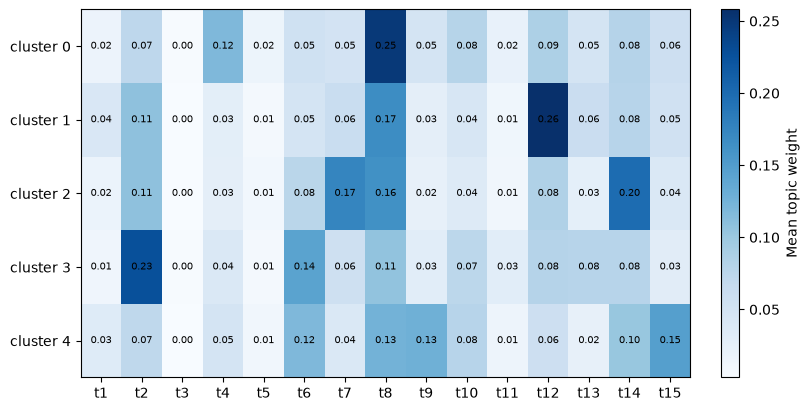

In [53]:
NCLUST = 5
R = NCLUST - 1                               # lecture rule; override to explore other r

Z = embed(R)
km = KMeans(NCLUST, n_init=50, random_state=0).fit(Z)
d["cluster"] = km.labels_
print(d["cluster"].value_counts().sort_index())

# which topics drive each embedding direction (standardized: right singular vectors)
if STANDARDIZE:
    for j in range(R):
        v = pd.Series(Vt[j], index=TS).sort_values()
        print(f"v{j+1}  low: {list(v.index[:4])}   high: {list(v.index[-4:])}")

# what each cluster talks about: mean raw topic weight per cluster (raw weights are easier to read)
profile = d.groupby("cluster")[T].mean()
fig, ax = plt.subplots(figsize=(8, 2 + .4 * len(profile)), layout="constrained")
im = ax.imshow(profile, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(T)), T)
ax.set_yticks(range(len(profile)), [f"cluster {c}" for c in profile.index])
for i in range(profile.shape[0]):
    for j in range(profile.shape[1]):
        ax.text(j, i, f"{profile.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="Mean topic weight")
plt.show()


In [32]:
# R, NCLUST = 4, 2

# Z = embed(R)
# km = KMeans(NCLUST, n_init=50, random_state=0).fit(Z)
# d["cluster"] = km.labels_

# print(d["cluster"].value_counts().sort_index())

# # what each cluster talks about: mean topic weight per cluster
# profile = d.groupby("cluster")[T].mean()
# fig, ax = plt.subplots(figsize=(8, 2 + .4 * len(profile)), layout="constrained")
# im = ax.imshow(profile, cmap="Blues", aspect="auto")
# ax.set_xticks(range(len(T)), T)
# ax.set_yticks(range(len(profile)), [f"cluster {c}" for c in profile.index])
# for i in range(profile.shape[0]):
#     for j in range(profile.shape[1]):
#         ax.text(j, i, f"{profile.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
# fig.colorbar(im, ax=ax, label="Mean topic weight")
# plt.show()

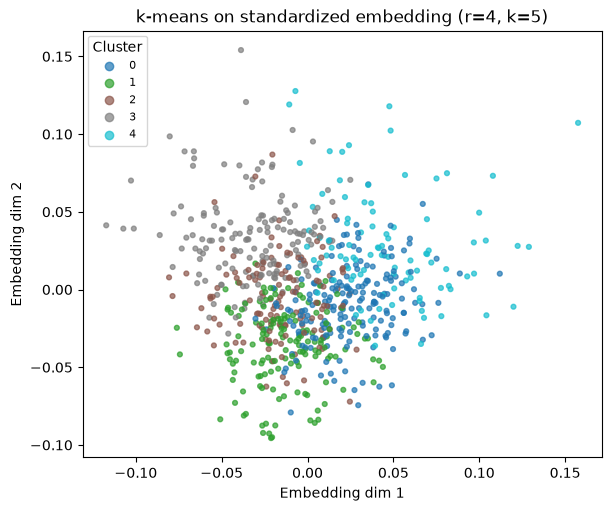

In [54]:
fig, ax = plt.subplots(figsize=(6, 4 if Z.shape[1] == 1 else 5), layout="constrained")
if Z.shape[1] == 1:   # 1-D embedding: histogram by cluster
    for c in sorted(d["cluster"].unique()):
        ax.hist(Z[d["cluster"] == c, 0], bins=40, alpha=.6, label=f"cluster {c}")
    ax.set(xlabel="Embedding dim 1", ylabel="Districts")
    ax.legend(fontsize=8)
else:
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=d["cluster"], cmap="tab10", s=12, alpha=.7)
    ax.set(xlabel="Embedding dim 1", ylabel="Embedding dim 2")
    ax.legend(*sc.legend_elements(), title="Cluster", fontsize=8)
ax.set_title(f"k-means on {'standardized' if STANDARDIZE else 'SCORE'} embedding (r={R}, k={NCLUST})")
plt.show()

In [34]:
# # clusters in the first two embedding coordinates
# fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
# sc = ax.scatter(Z[:, 0], Z[:, 1], c=d["cluster"], cmap="tab10", s=12, alpha=.7)
# ax.set(xlabel="Embedding dim 1", ylabel="Embedding dim 2", title=f"k-means on left singular vectors (r={R}, k={NCLUST})")
# ax.legend(*sc.legend_elements(), title="Cluster", fontsize=8)
# plt.show()

## Add partisanship and geography covariates

In [55]:
from scipy import stats

static = pd.read_parquet("Datastore/District Covariates/processed/district_static.parquet")
LOCALE = {1: "City", 2: "Suburb", 3: "Town", 4: "Rural"}
REGION = {**dict.fromkeys("CT ME MA NH RI VT NJ NY PA".split(), "Northeast"),
          **dict.fromkeys("IL IN MI OH WI IA KS MN MO NE ND SD".split(), "Midwest"),
          **dict.fromkeys("DE DC FL GA MD NC SC VA WV AL KY MS TN AR LA OK TX".split(), "South"),
          **dict.fromkeys("AZ CO ID MT NV NM UT WY AK CA HI OR WA".split(), "West")}

cov = static[["leaid", "lea_name", "state_location", "latitude", "longitude", "urban_centric_locale", "gop_2p_2020"]].copy()
cov["locale"] = (pd.to_numeric(cov["urban_centric_locale"], errors="coerce") // 10).map(LOCALE)
cov["region"] = cov["state_location"].map(REGION)

d = d.drop(columns=cov.columns.drop("leaid"), errors="ignore").merge(cov, on="leaid", how="left")
print(f"merge: {d['lea_name'].notna().mean():.1%} matched; "
      f"gop_2p_2020 {d['gop_2p_2020'].notna().mean():.1%}, locale {d['locale'].notna().mean():.1%}")

merge: 100.0% matched; gop_2p_2020 99.9%, locale 100.0%


### Check partisanship alignment

,count,mean,25%,50%,75%
cluster,,,,,
0,185.0,0.523,0.411,0.500,0.644
1,151.0,0.456,0.370,0.451,0.540
2,129.0,0.451,0.362,0.442,0.559
3,154.0,0.501,0.380,0.500,0.633
4,94.0,0.516,0.396,0.495,0.636


Kruskal-Wallis: KruskalResult(statistic=np.float64(24.086213569582675), pvalue=np.float64(7.675845564442501e-05))
eta^2 (cluster -> GOP share) = 0.038; permutation p within locale = 0.0178


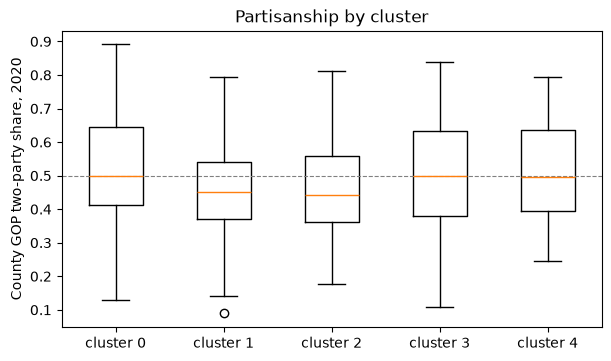

In [56]:
p = d.dropna(subset=["gop_2p_2020"])

display(p.groupby("cluster")["gop_2p_2020"].describe()[["count", "mean", "25%", "50%", "75%"]].round(3))
print("Kruskal-Wallis:", stats.kruskal(*[g["gop_2p_2020"] for _, g in p.groupby("cluster")]))

def eta2(y, g):
    """share of variance in y explained by group means of g"""
    return y.groupby(g).transform("mean").var() / y.var()

def within_strata_perm(y, g, strata, n=5000, seed=0):
    """permutation p-value for eta2(y, g), shuffling g only within strata"""
    rng = np.random.default_rng(seed)
    obs = eta2(y, g)
    idx = [np.flatnonzero(strata.to_numpy() == s) for s in strata.unique()]
    gv, null = g.to_numpy(), np.empty(n)
    for b in range(n):
        gp = gv.copy()
        for ix in idx:
            gp[ix] = rng.permutation(gv[ix])
        null[b] = eta2(y, pd.Series(gp, index=y.index))
    return obs, (null >= obs).mean()

pl = p.dropna(subset=["locale"])
obs, pval = within_strata_perm(pl["gop_2p_2020"], pl["cluster"], pl["locale"])
print(f"eta^2 (cluster -> GOP share) = {obs:.3f}; permutation p within locale = {pval:.4f}")

fig, ax = plt.subplots(figsize=(6, 3.5), layout="constrained")
ax.boxplot([g["gop_2p_2020"] for _, g in p.groupby("cluster")], tick_labels=[f"cluster {c}" for c in sorted(p["cluster"].unique())])
ax.axhline(.5, color="gray", lw=.8, ls="--")
ax.set(ylabel="County GOP two-party share, 2020", title="Partisanship by cluster")
plt.show()


### Check geography


locale: Cramer's V = 0.156, chi-square p = 5.679e-07  (row %)


locale,City,Rural,Suburb,Town
cluster,,,,
0,10.8,35.1,33.5,20.5
1,30.3,15.1,43.4,11.2
2,20.2,18.6,51.2,10.1
3,18.2,20.1,48.1,13.6
4,16.0,25.5,37.2,21.3



region: Cramer's V = 0.101, chi-square p = 0.04105  (row %)


region,Midwest,Northeast,South,West
cluster,,,,
0,35.7,24.9,16.2,23.2
1,34.2,23.0,17.1,25.7
2,25.6,27.9,26.4,20.2
3,35.1,26.6,22.7,15.6
4,33.0,19.1,33.0,14.9


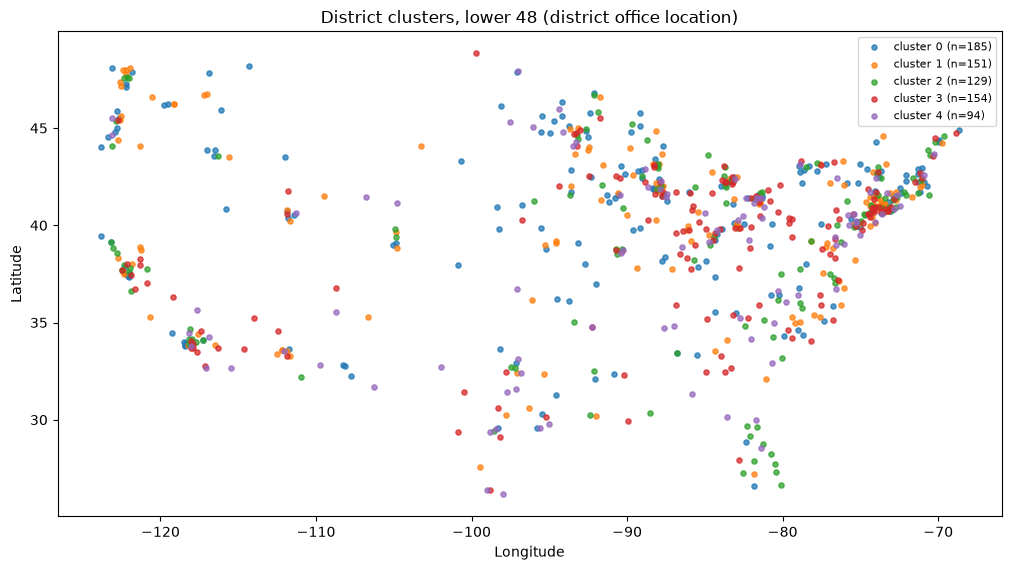

In [57]:
def cramers_v(ct):
    chi2, pval, *_ = stats.chi2_contingency(ct)
    return np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1))), pval

for var in ["locale", "region"]:
    ct = pd.crosstab(d["cluster"], d[var])
    v, pval = cramers_v(ct)
    print(f"\n{var}: Cramer's V = {v:.3f}, chi-square p = {pval:.4g}  (row %)")
    display((pd.crosstab(d["cluster"], d[var], normalize="index") * 100).round(1))

m = d[d["longitude"].between(-125, -66) & d["latitude"].between(24, 50)]  # lower 48
fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
for c, g in m.groupby("cluster"):
    ax.scatter(g["longitude"], g["latitude"], s=14, alpha=.75, label=f"cluster {c} (n={len(g)})")
ax.set(xlabel="Longitude", ylabel="Latitude", title="District clusters, lower 48 (district office location)")
ax.set_aspect(1.25)
ax.legend(fontsize=8)
plt.show()

## IF-PCA

In [47]:
import sys, joblib
from scipy import sparse, stats
from sklearn.metrics import adjusted_rand_score

sys.path.insert(0, "source/analysis/lda_2018_2023")
import workflow  # noqa: F401  (needed to unpickle the vectorizer)

WORK = Path("Datastore/DistrictView/derived/lda_cleaned") / TAG
vec = joblib.load(WORK / "vectorizer.joblib")
words = vec.get_feature_names_out()

In [48]:
# district x word counts from the chunk text
mats, ids = [], []
for f in sorted((WORK / "chunks").glob("*.parquet")):
    c = pd.read_parquet(f, columns=["leaid", "text"])
    mats.append(vec.transform(c["text"]))
    ids.append(c["leaid"].astype(str).str.zfill(7))
C = sparse.vstack(mats).tocsr()
codes, leaids = pd.factorize(pd.concat(ids, ignore_index=True))
G = sparse.csr_matrix((np.ones(len(codes)), (codes, np.arange(len(codes)))), shape=(len(leaids), len(codes)))
D = (G @ C).toarray()

keep = (D > 0).mean(0) >= .2                     # words used in >= 20% of districts
Dk, W = D[:, keep], words[keep]
n, p = Dk.shape

In [49]:
# step 1: rank words by over-dispersion vs "same rate in every district" (multinomial null)
E = D.sum(1, keepdims=True) * (Dk.sum(0) / D.sum())
chi = ((Dk - E) ** 2 / E).sum(0)
lz = np.log(chi / (n - 1))
zs = (lz - np.median(lz)) / (1.4826 * np.median(np.abs(lz - np.median(lz))))   # Efron empirical null
pv = stats.norm.sf(zs)

In [50]:
# step 2: HC threshold (lecture slide 21)
ps, k = np.sort(pv), np.arange(1, p + 1)
hc = np.sqrt(p) * (k / p - ps) / np.sqrt(k / p + np.maximum(np.sqrt(n) * (k / p - ps), 0))
ok = (k <= p / 2) & (ps > np.log(p) / p)
khat = k[ok][np.argmax(hc[ok])]
sel = np.argsort(pv)[:khat]
print(f"HC keeps {khat} of {p} words; top 40:", list(W[sel[:40]]))

HC keeps 388 of 2760 words; top 40: ['mrs', 'street', 'pool', 'mr', 'yes', 'aye', 'mask', 'motion', 'parking', 'director', 'county', 'budget', 'band', 'lease', 'chair', 'foreign', 'policy', 'miss', 'president', 'city', 'book', 'masks', 'board', 'trustees', 'dr', 'town', 'levy', 'feet', 'bond', 'books', 'tier', 'york', 'madam', 'fund', 'million', 'students', 'gender', 'lake', 'property', 'wall']


In [51]:
# step 3: spectral clustering on standardized sqrt-frequencies of the selected words
Xw = np.sqrt(Dk / D.sum(1, keepdims=True))
Xs = ((Xw - Xw.mean(0)) / Xw.std(0))[:, sel]
Uw, sw, Vw = np.linalg.svd(Xs, full_matrices=False)
for j in range(2):
    o = np.argsort(Vw[j])
    print(f"v{j+1}  low:", list(W[sel][o[:12]]), "\n    high:", list(W[sel][o[-12:]]))

v1  low: ['dollars', 'million', 'fund', 'money', 'revenue', 'thousand', 'funds', 'expenditures', 'cost', 'pay', 'balance', 'tax'] 
    high: ['day', 'data', 'kids', 'student', 'support', 'teachers', 'grade', 'parents', 'community', 'children', 'learning', 'students']
v2  low: ['data', 'level', 'learning', 'students', 'assessment', 'grade', 'math', 'growth', 'slide', 'classes', 'really', 'standards'] 
    high: ['treasurer', 'president', 'yes', 'superintendent', 'approve', 'agenda', 'favor', 'mr', 'board', 'second', 'motion', 'meeting']


In [52]:
NC = 2
ifpca = pd.DataFrame({"leaid": leaids, "cluster_ifpca": KMeans(NC, n_init=50, random_state=0).fit_predict(Uw[:, :NC - 1]),
                      "u1": Uw[:, 0]})
cmp = d.merge(ifpca, on="leaid")
print("ARI vs topic clusters:", round(adjusted_rand_score(cmp["cluster"], cmp["cluster_ifpca"]), 3))
display(cmp.groupby("cluster_ifpca")["gop_2p_2020"].agg(["count", "mean"]).round(3))
display((pd.crosstab(cmp["cluster_ifpca"], cmp["locale"], normalize="index") * 100).round(1))

ARI vs topic clusters: 0.44


,count,mean
cluster_ifpca,,
0,400,0.470
1,313,0.516


locale,City,Rural,Suburb,Town
cluster_ifpca,,,,
0,23.7,19.2,45.4,11.7
1,12.8,28.8,38.7,19.8
